# Разведочный анализ

### Импорт библиотек для работы

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Сохранение датасета в переменную data

In [3]:
data = pd.read_csv("../data/train.csv")

### Описание признаков

In [8]:
print("Первые 5 строк для проверки:")
data.head()

Первые 5 строк для проверки:


,sku,unit,2019-01,2019-02,2019-03,2019-04,2019-05,2019-06,2019-07,2019-08,...,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11
0,0,ШТ,128.0,125.0,179.0,199.0,204.0,246.0,172.0,235.0,...,379.0,250.0,317.0,172.0,193.0,173.0,121.0,318.0,328.0,208.0
1,1,ШТ,65.0,64.0,54.0,91.0,74.0,91.0,138.0,115.0,...,68.0,65.0,72.0,82.0,85.0,69.0,75.0,100.0,72.0,89.0
2,2,ШТ,157.0,205.0,210.0,205.0,265.0,248.0,292.0,268.0,...,334.0,380.0,409.0,309.0,388.0,438.0,404.0,293.0,274.0,381.0
3,3,ШТ,2450.0,2280.0,2144.0,2283.0,2177.0,2888.0,3066.0,2288.0,...,2806.0,2085.0,1984.0,2086.0,2871.0,2204.0,1821.0,2187.0,1672.0,1665.0
4,4,ШТ,119.0,154.0,154.0,270.0,513.0,718.0,720.0,292.0,...,222.0,258.0,289.0,662.0,759.0,616.0,365.0,321.0,392.0,409.0


In [19]:
data['unit'].value_counts()

unit
ШТ     1232
УП      139
Меш      69
КГ       52
Лст      47
Пм       27
РУЛ      23
М        21
ПАР      17
Вдр      17
ПК        5
Кмп       4
Мкр       2
Бнк       1
Name: count, dtype: int64

In [20]:
month_cols = data.columns[2:]
data['total_sales'] = data[month_cols].sum(axis=1)

top_10 = data.sort_values(by='total_sales', ascending=False).head(10)
top_10_share = (top_10['total_sales'].sum() / data['total_sales'].sum()) * 100

zero_skus = data[data['total_sales'] == 0]

print(f"Доля топ-10 товаров от общего объёма: {top_10_share:.1f}%")
print(f"Количество товаров без единой продажи: {len(zero_skus)}")


top_10[['sku', 'unit', 'total_sales']]

Доля топ-10 товаров от общего объёма: 31.6%
Количество товаров без единой продажи: 3


,sku,unit,total_sales
568,568,ШТ,8913948.0
1619,1619,ШТ,7516695.0
576,576,ШТ,5982127.0
166,166,ШТ,4859353.0
982,982,ШТ,4786320.0
577,577,ШТ,4371834.0
1395,1395,ШТ,2921742.0
281,281,ШТ,2782130.0
222,222,ШТ,2209666.0
1510,1510,ШТ,1971131.0


- В наборе 37 столбцов. 

1) sku - уникальный идентификатор товара.
2) unit - единица измерения (всего 14 типов). Доминируют штуки (ШТ: 1232 товара), далее идут упаковки (УП: 139), мешки (Меш: 69) и килограммы (КГ: 52).
3) 2019-01 - 2021-11 (35 столбцов) - история помесячных объёмов продаж.

- Что уже понятно:

1) Всего 10 товаров генерируют 31.6% всего суммарного объёма продаж сети. Все эти 10 товаров штучные. Это означает, что ошибка прогноза на этих ключевых позициях окажет решающее влияние на метрику WAPE.
2) Обнаружено ровно 3 SKU с нулевыми продажами за все 35 месяцев. Для них логично зафиксировать нулевой прогноз.
3) Из-за сильного различия в единицах измерения и масштабах (от единиц до миллионов) метрика WAPE практически не заметит ошибки на мелких товарах. Поэтому метрика MASE необходима для объективной оценки каждого отдельного SKU в его собственном масштабе.

### Проверка на пропуски

In [9]:
print("Базовая справка о датасете:")
data.info()

Базовая справка о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1656 entries, 0 to 1655
Data columns (total 37 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   sku      1656 non-null   int64  
 1   unit     1656 non-null   object 
 2   2019-01  1656 non-null   float64
 3   2019-02  1656 non-null   float64
 4   2019-03  1656 non-null   float64
 5   2019-04  1656 non-null   float64
 6   2019-05  1656 non-null   float64
 7   2019-06  1656 non-null   float64
 8   2019-07  1656 non-null   float64
 9   2019-08  1656 non-null   float64
 10  2019-09  1656 non-null   float64
 11  2019-10  1656 non-null   float64
 12  2019-11  1656 non-null   float64
 13  2019-12  1656 non-null   float64
 14  2020-01  1656 non-null   float64
 15  2020-02  1656 non-null   float64
 16  2020-03  1656 non-null   float64
 17  2020-04  1656 non-null   float64
 18  2020-05  1656 non-null   float64
 19  2020-06  1656 non-null   float64
 20  2020-07  1656 non-null  

In [13]:
display(data.isna().sum())

sku        0
unit       0
2019-01    0
2019-02    0
2019-03    0
2019-04    0
2019-05    0
2019-06    0
2019-07    0
2019-08    0
2019-09    0
2019-10    0
2019-11    0
2019-12    0
2020-01    0
2020-02    0
2020-03    0
2020-04    0
2020-05    0
2020-06    0
2020-07    0
2020-08    0
2020-09    0
2020-10    0
2020-11    0
2020-12    0
2021-01    0
2021-02    0
2021-03    0
2021-04    0
2021-05    0
2021-06    0
2021-07    0
2021-08    0
2021-09    0
2021-10    0
2021-11    0
dtype: int64

Как видно, после метода info видно, что в наборе нету null значений, дополнительная проверка, с помощью isna.sum показала то же самое, в каждом столбце сумма пропусков равна нулю. 

### Проверка на нули и отрицательные значения

In [14]:
# Функция для подсчёта нулевых и отрицательных значений в каждом месяце
def get_summary_df(data):
    results = []
    
    for col in data.columns[2:]:
        zero_data = (data[col] == 0).sum()
        under_zero_data = (data[col] < 0).sum()
        all_data = zero_data + under_zero_data
        results.append({
            "Название столбца": col,
            "Значений меньше нуля": under_zero_data,
            "Нулевых значений": zero_data,
            "Всего нулевых и отрицательных значений": all_data
        })
        
    return pd.DataFrame(results)

get_summary_df(data)

,Название столбца,Значений меньше нуля,Нулевых значений,Всего нулевых и отрицательных значений
0,2019-01,0,212,212
1,2019-02,0,210,210
2,2019-03,0,195,195
3,2019-04,0,175,175
4,2019-05,1,164,165
5,2019-06,0,164,164
6,2019-07,0,151,151
7,2019-08,0,142,142
8,2019-09,0,146,146
9,2019-10,0,143,143


- Нулевые значения: в каждом месяце имеются нулевые продажи. Это нормальная ситуация для розницы (низкий спрос, сезонность или временное отсутствие товара на складе). При масштабировании данных заменять их на другие значения(например, медиану или среднее) нельзя - т.к это нормальная ситуация в рознице и при замене таких данных модель в будущем будет иметь огромные метрики.

- Отрицательные значения: встречаются единично. Это возвраты товаров. При подготовке признаков их можно безопасно скорректировать, чтобы они не сбивали обучение.

### Визуальное описание.

In [16]:
# создание серии, где индекс это название месяца, а значение - общее кол-во продаж в этом месяце
sales_by_month = data[data.columns[2:]].sum()

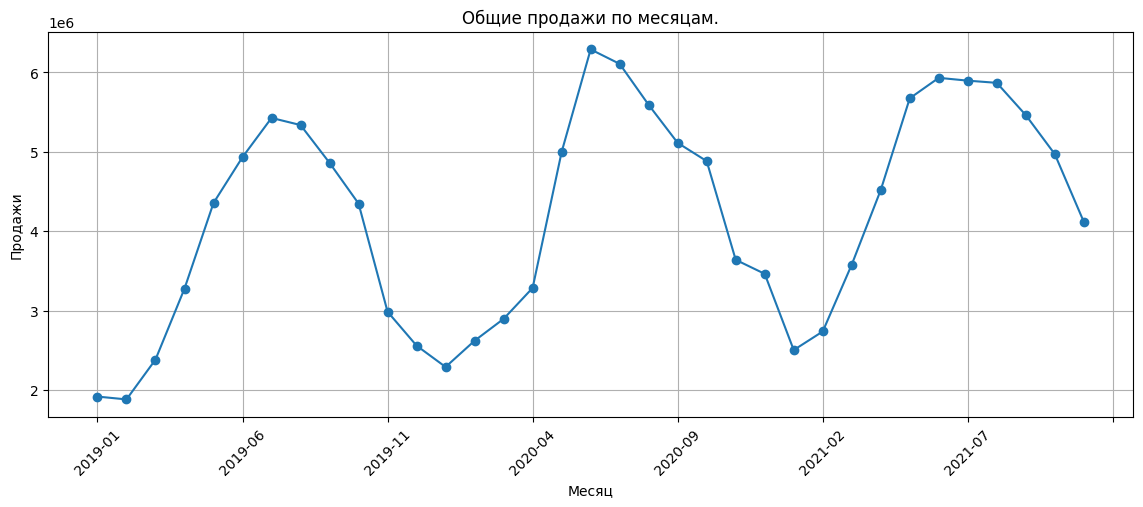

In [18]:
plt.figure(figsize=(14, 5))
sales_by_month.plot(kind='line', marker='o')
plt.title('Общие продажи по месяцам.')
plt.xlabel('Месяц')
plt.ylabel('Продажи')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

Как видно, летом общие продажи преобладают, зимой они намного меньше, спады и подъемы приходяться на осень и весну. Свои максимальные значения по продажам месяца получают летом, а зимой => минимальные